In [ ]:
!pip install pandas openai python-dotenv tqdm openpyxl
!pip show openai

Name: openai
Version: 1.91.0
Summary: The official Python library for the openai API
Home-page: https://github.com/openai/openai-python
Author: 
Author-email: OpenAI <support@openai.com>
License: Apache-2.0
Location: /usr/local/lib/python3.11/dist-packages
Requires: anyio, distro, httpx, jiter, pydantic, sniffio, tqdm, typing-extensions
Required-by: 


In [ ]:
import os
import pandas as pd
import openai
from dotenv import load_dotenv
from tqdm import tqdm
from openai import OpenAI

In [ ]:
# .env file loading (api key)
load_dotenv()

# api key defining
os.environ["OPENAI_API_KEY"]  = "OPENAI_API_KEY"
# client = OpenAI(api_key="sOPENAI_API_KEY")
client = OpenAI(api_key=openai.api_key) #OPENAI_API_KEY

In [ ]:
# prompt
prompt_template = """
You are a classification assistant.
Your task is to categorize academic papers based only on their title and abstract.

You will be provided with:
•⁠  ⁠Title: the paper's title
•⁠  ⁠Abstract: the paper's abstract

Classify the paper into exactly one of the following three types:

type_1: The paper focuses on nurses conducting research.

type_2: The paper focuses on nurses implementing research findings in clinical settings (i.e., Evidence-Based Practice - EBP).

type_3: The paper does not focus exclusively on either conducting or implementing research, but instead discusses both aspects more or less equally.

If uncertain, choose the type that best reflects the core emphasis of the abstract and title.

Now, analyze and classify the following based on the title and abstract provided:
_
Title: {title}
Abstract: {abstract}
_

Return your answer in exactly the following format:

Decision: <type_1 / type_2 / type_3>
Explain: <Brief explanation referencing the relevant type definition>
"""


In [ ]:
def classify_paper(title: str, abstract: str):
    # prompt defining with 'title' and 'abstract'
    prompt = prompt_template.format(title=title, abstract=abstract)

    try:
        response = client.chat.completions.create(
            model="gpt-4o",  # USING GPT-4o !
            messages=[{"role": "user", "content": prompt}],
            temperature=0.0,  # for determination
            max_tokens=150    # limit the answer's length

        )

        answer = response.choices[0].message.content.strip()

        decision = ""
        explanation = ""
        if "**Decision:**" in answer:

            parts = answer.split("**Explain:**")
            decision_part = parts[0]
            explanation_part = parts[1] if len(parts) > 1 else ""

            decision = decision_part.replace("**Decision:**", "").strip()
            explanation = explanation_part.strip()
        elif "Decision:" in answer:

            parts = answer.split("Explanation:") if "Explanation:" in answer else answer.split("Explain:")
            decision_part = parts[0]
            explanation_part = parts[1] if len(parts) > 1 else ""
            decision = decision_part.replace("Decision:", "").strip()
            explanation = explanation_part.strip()
        else:

            explanation = answer

        return decision, explanation
    except Exception as e:
        print(f"Error classifying paper with title: {title}\nError: {e}")
        return None, None



In [1]:
import pandas as pd

In [2]:
# paper's excel loading
df = pd.read_excel("478_without_review_3.xlsx")
print("Columns in the csv file:", df.columns)


Columns in the csv file: Index(['PubMed ID', 'DOI', 'Title', 'Year', 'Abstract', 'Author Keywords',
       'english', 'Title_lower', 'Decision', 'Decision Type', 'Type_article',
       'Extracted_Number'],
      dtype='object')


In [3]:
df.shape

(478, 12)

In [3]:
from tqdm import tqdm

decisions = []
explanations = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Classifying papers"):
    title = row["Title"]
    abstract = row["Abstract"]
    dec, exp = classify_paper(title, abstract)
    decisions.append(dec)
    explanations.append(exp)


In [ ]:
# Add new columns to the DataFrame
df["Classification"] = decisions
df["Explanation"] = explanations

# Preview first 5 rows
print(df.head())

# Save to Excel
output_file = "478_classified_with_type_4.xlsx"
df.to_excel(output_file, index=False, engine='openpyxl')

print(f"✅ Results saved to {output_file}")


    PubMed ID                                 DOI  \
0  12470013.0           10.1016/s0964339702000125   
1  18838895.0  10.1097/01.NND.0000320688.57308.f9   
2  18710376.0    10.1111/j.1365-2702.2007.02040.x   
3  18243707.0          10.1016/j.iccn.2007.12.001   
4  15761309.0    10.1097/00005110-200503000-00005   

                                               Title  Year  \
0  Barriers to research utilisation: the clinical...  2002   
1  Nursing faculty mentors as facilitators for ev...  2008   
2  The spectrum of barriers to and facilitators o...  2008   
3  Research activities and perceptions of barrier...  2008   
4  Overcoming barriers and promoting the use of r...  2005   

                                            Abstract Author Keywords english  \
0  The advance of the evidence-based practice (EB...              []      en   
1  Increasing use of evidence-based practice (EBP...              []      en   
2  The focus of the study is the identification o...              []

In [ ]:
# # adding new columns to the excel file
# df["Classification"] = decisions
# df["Explanation"] = explanations

# # first 5 lines for check
# df.head()
# # saving the new
# output_file = "486_classified_with_type_5.csv"
# df.to_csv(output_file, index=False,encoding='utf-8')
# print(f"Results saved to {output_file}")


Results saved to 486_classified_with_type_5.csv


In [8]:
df.Classification.value_counts()

,count
Classification,
type_2,257
type_1,139
type_3,82


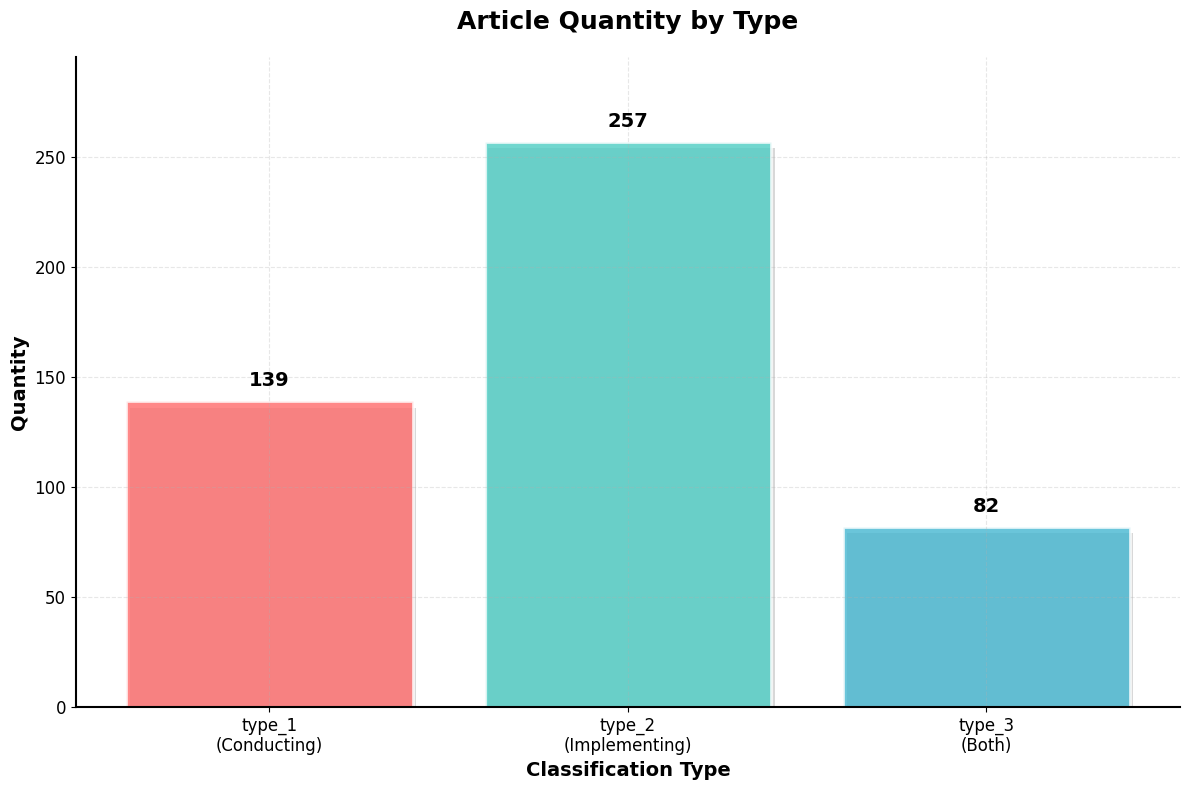

=== Data Summary ===
Total articles: 478
type_1 (Conducting): 139 (29.1%)
type_2 (Implementing): 257 (53.8%)
type_3 (Both): 82 (17.2%)


In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Data from the table
categories = ['type_1\n(Conducting)', 'type_2\n(Implementing)', 'type_3\n(Both)']
values = [139, 257, 82]

# Create the chart
plt.figure(figsize=(12, 8))

# Create bars with gradient colors
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
bars = plt.bar(categories, values, color=colors, alpha=0.8, edgecolor='white', linewidth=2)

# Add values above bars
for bar, value in zip(bars, values):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 5,
             f'{value}', ha='center', va='bottom', fontsize=14, fontweight='bold')

# Chart styling
plt.title('Article Quantity by Type', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Classification Type', fontsize=14, fontweight='bold')
plt.ylabel('Quantity', fontsize=14, fontweight='bold')

# Add background grid
plt.grid(True, alpha=0.3, linestyle='--')

# Set axis limits
plt.ylim(0, max(values) * 1.15)

# Style the axes
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Add frame to the chart
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

# Add shadow to bars
for i, bar in enumerate(bars):
    # Create shadow
    shadow = plt.Rectangle((bar.get_x() + 0.01, bar.get_y() - 3),
                          bar.get_width(), bar.get_height(),
                          facecolor='gray', alpha=0.3, zorder=0)
    ax.add_patch(shadow)

# Adjust layout
plt.tight_layout()

# Display the chart
plt.show()

# Print data summary
print("=== Data Summary ===")
print(f"Total articles: {sum(values)}")
print(f"type_1 (Conducting): {values[0]} ({values[0]/sum(values)*100:.1f}%)")
print(f"type_2 (Implementing): {values[1]} ({values[1]/sum(values)*100:.1f}%)")
print(f"type_3 (Both): {values[2]} ({values[2]/sum(values)*100:.1f}%)")